# 3.1 Six métriques visuelles + 5 classifieurs : Dataset 1

6 mesures par image (largeur, hauteur, luminosité, contraste, densité d'encre, format) et 5 classifieurs
du cours. Même découpage pour tous ; les hyperparamètres sont choisis par validation croisée sur le
train, le test ne sert qu'à la fin.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from tqdm import tqdm
from xgboost import XGBClassifier, plot_importance

from outils_3 import list_images

DOSSIER = "../data/document-classification-dataset_1"

## Les 6 métriques visuelles de chaque image

In [2]:
df = list_images(DOSSIER)

lignes = []
for chemin in tqdm(df["filepath"]):
    image = Image.open(chemin).convert("L")
    pixels = np.array(image, dtype=np.float32)
    largeur, hauteur = image.size
    lignes.append({"width": largeur,
                   "height": hauteur,
                   "brightness": pixels.mean(),
                   "contrast": pixels.std(),
                   "dark_ratio": (pixels < 128).mean(),  # pixels sombres
                   "aspect_ratio": largeur / hauteur})

X = pd.DataFrame(lignes)
y = df["label"]
X.head()

  0%|          | 0/165 [00:00<?, ?it/s]

 23%|██▎       | 38/165 [00:00<00:00, 370.66it/s]

 46%|████▌     | 76/165 [00:00<00:00, 366.75it/s]

 70%|██████▉   | 115/165 [00:00<00:00, 374.98it/s]

100%|██████████| 165/165 [00:00<00:00, 405.56it/s]

,width,height,brightness,contrast,dark_ratio,aspect_ratio
0,754,1000,234.411835,56.726704,0.079191,0.754
1,754,1000,240.997070,49.562576,0.053436,0.754
2,754,1000,241.733978,47.606915,0.051590,0.754
3,754,1000,227.461349,65.343468,0.103828,0.754
4,754,1000,237.165939,50.567986,0.067845,0.754


## Préparation des données (commune aux 5 modèles)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

resultats = {}
print(f"Train : {len(X_train)} | Test : {len(X_test)}")

Train : 132 | Test : 33


## 1. SVM

In [4]:
grid_svm = GridSearchCV(SVC(), {"C": [0.1, 1, 10],
                                "kernel": ["rbf", "linear", "poly"],
                                "gamma": [0.001, 0.1, 0.5]}, cv=5)
grid_svm.fit(X_train_s, y_train)
print("Meilleurs paramètres :", grid_svm.best_params_)
print(f"Score en validation croisée : {grid_svm.best_score_:.3f}")

y_pred = grid_svm.predict(X_test_s)
resultats["SVM"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['SVM']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Meilleurs paramètres : {'C': 10, 'gamma': 0.5, 'kernel': 'poly'}
Score en validation croisée : 0.758
Accuracy test : 0.758


prédit,email,resume,scientific_publication
réel,,,
email,8,0,0
resume,3,9,2
scientific_publication,0,3,8


## 2. KNN

k et la distance sont choisis par validation croisée. La courbe donne le score selon k.

Meilleurs paramètres : {'metric': 'manhattan', 'n_neighbors': 13}
Score en validation croisée : 0.773


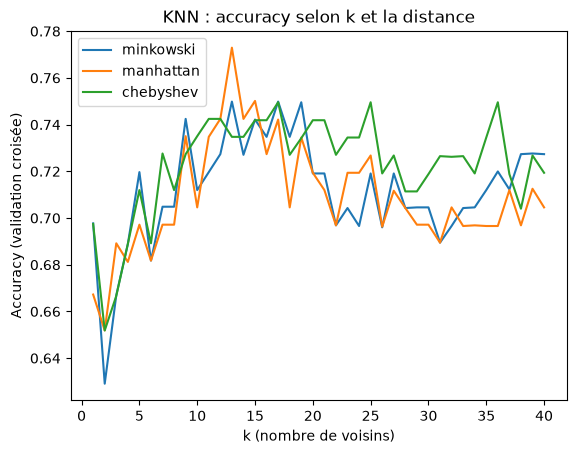

In [5]:
grid_knn = GridSearchCV(KNeighborsClassifier(), {"n_neighbors": range(1, 41),
                                                 "metric": ["minkowski", "manhattan", "chebyshev"]}, cv=5)
grid_knn.fit(X_train_s, y_train)
print("Meilleurs paramètres :", grid_knn.best_params_)
print(f"Score en validation croisée : {grid_knn.best_score_:.3f}")

scores = pd.DataFrame(grid_knn.cv_results_)
for distance in ["minkowski", "manhattan", "chebyshev"]:
    sous_scores = scores[scores["param_metric"] == distance]
    plt.plot(sous_scores["param_n_neighbors"], sous_scores["mean_test_score"], label=distance)
plt.xlabel("k (nombre de voisins)")
plt.ylabel("Accuracy (validation croisée)")
plt.title("KNN : accuracy selon k et la distance")
plt.legend()
plt.show()

In [6]:
y_pred = grid_knn.predict(X_test_s)
resultats["KNN"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['KNN']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Accuracy test : 0.697


prédit,email,resume,scientific_publication
réel,,,
email,8,0,0
resume,4,8,2
scientific_publication,0,4,7


## 3. Arbre de décision

Deux critères comparés, profondeur 4. Pas besoin de standardiser pour un arbre.

In [7]:
for critere in ["entropy", "gini"]:
    arbre = DecisionTreeClassifier(criterion=critere, max_depth=4, random_state=123)
    arbre.fit(X_train, y_train)
    print(f"Accuracy test ({critere}) : {arbre.score(X_test, y_test):.3f}")

arbre = DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=123).fit(X_train, y_train)
y_pred = arbre.predict(X_test)
resultats["Arbre de décision"] = accuracy_score(y_test, y_pred)
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Accuracy test (entropy) : 0.636
Accuracy test (gini) : 0.636


prédit,email,resume,scientific_publication
réel,,,
email,8,0,0
resume,4,8,2
scientific_publication,0,6,5


In [8]:
pd.Series(arbre.feature_importances_, index=X.columns).sort_values(ascending=False)

brightness      0.709721
aspect_ratio    0.160275
contrast        0.130005
width           0.000000
height          0.000000
dark_ratio      0.000000
dtype: float64

## 4. XGBoost

XGBoost veut des classes numérotées, d'où le `LabelEncoder`.

Meilleurs paramètres : {'colsample_bytree': 0.7, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Score en validation croisée (f1) : 0.682


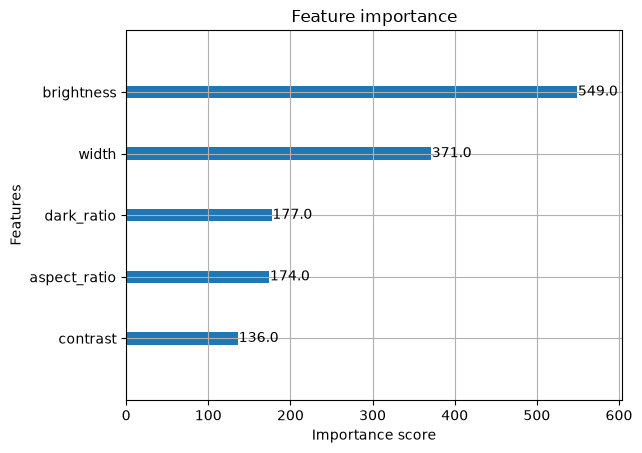

In [9]:
encodeur = LabelEncoder().fit(y_train)

grid_xgb = GridSearchCV(XGBClassifier(eval_metric="mlogloss"),
                        {"n_estimators": [100, 300, 500],
                         "learning_rate": [0.01, 0.05, 0.1],
                         "max_depth": [3, 5, 7],
                         "subsample": [0.7, 0.9, 1.0],
                         "colsample_bytree": [0.7, 0.9, 1.0]},
                        cv=5, scoring="f1_weighted", n_jobs=-1)
grid_xgb.fit(X_train, encodeur.transform(y_train))
print("Meilleurs paramètres :", grid_xgb.best_params_)
print(f"Score en validation croisée (f1) : {grid_xgb.best_score_:.3f}")

plot_importance(grid_xgb.best_estimator_)
plt.show()

In [10]:
y_pred = encodeur.inverse_transform(grid_xgb.predict(X_test))
resultats["XGBoost"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['XGBoost']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Accuracy test : 0.697


prédit,email,resume,scientific_publication
réel,,,
email,8,0,0
resume,4,8,2
scientific_publication,0,4,7


## 5. Random Forest

50 combinaisons d'hyperparamètres tirées au hasard (`RandomizedSearchCV`).

In [11]:
recherche_rf = RandomizedSearchCV(RandomForestClassifier(n_jobs=-1, random_state=321),
                                  {"n_estimators": [100, 300, 500],
                                   "max_depth": [None, 5, 10, 20],
                                   "min_samples_split": [2, 5, 10],
                                   "min_samples_leaf": [1, 2, 4],
                                   "max_features": ["sqrt", "log2", None],
                                   "class_weight": ["balanced", None]},
                                  n_iter=50, cv=5, scoring="f1_weighted", n_jobs=-1, random_state=42)
recherche_rf.fit(X_train, y_train)
print("Meilleurs paramètres :", recherche_rf.best_params_)
print(f"Score en validation croisée (f1) : {recherche_rf.best_score_:.3f}")

y_pred = recherche_rf.predict(X_test)
resultats["Random Forest"] = accuracy_score(y_test, y_pred)
print(f"Accuracy test : {resultats['Random Forest']:.3f}")
pd.crosstab(y_test, y_pred, rownames=["réel"], colnames=["prédit"])

Meilleurs paramètres : {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5, 'class_weight': 'balanced'}
Score en validation croisée (f1) : 0.700
Accuracy test : 0.697


prédit,email,resume,scientific_publication
réel,,,
email,8,0,0
resume,4,8,2
scientific_publication,0,4,7


### Courbe de gain cumulatif

Documents du test triés par probabilité : part de la classe déjà retrouvée.

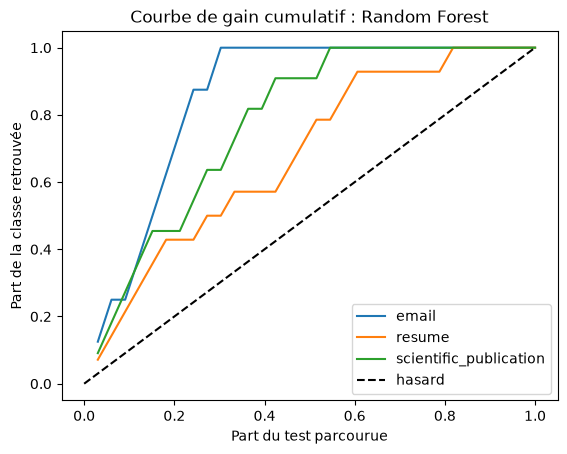

In [12]:
probas = recherche_rf.predict_proba(X_test)
part_du_test = np.arange(1, len(y_test) + 1) / len(y_test)
for i, classe in enumerate(recherche_rf.classes_):
    ordre = np.argsort(probas[:, i])[::-1]
    gains = np.cumsum(y_test.values[ordre] == classe) / (y_test == classe).sum()
    plt.plot(part_du_test, gains, label=classe)
plt.plot([0, 1], [0, 1], "k--", label="hasard")
plt.xlabel("Part du test parcourue")
plt.ylabel("Part de la classe retrouvée")
plt.title("Courbe de gain cumulatif : Random Forest")
plt.legend()
plt.show()

## Résumé : accuracy sur le test

In [13]:
pd.Series(resultats, name="accuracy").sort_values(ascending=False).round(3)

SVM                  0.758
KNN                  0.697
XGBoost              0.697
Random Forest        0.697
Arbre de décision    0.636
Name: accuracy, dtype: float64